✅ Studies processed: ['AF', 'BC', 'DOU', 'JIN', 'LOU', 'PGL', 'POI', 'ZAN']


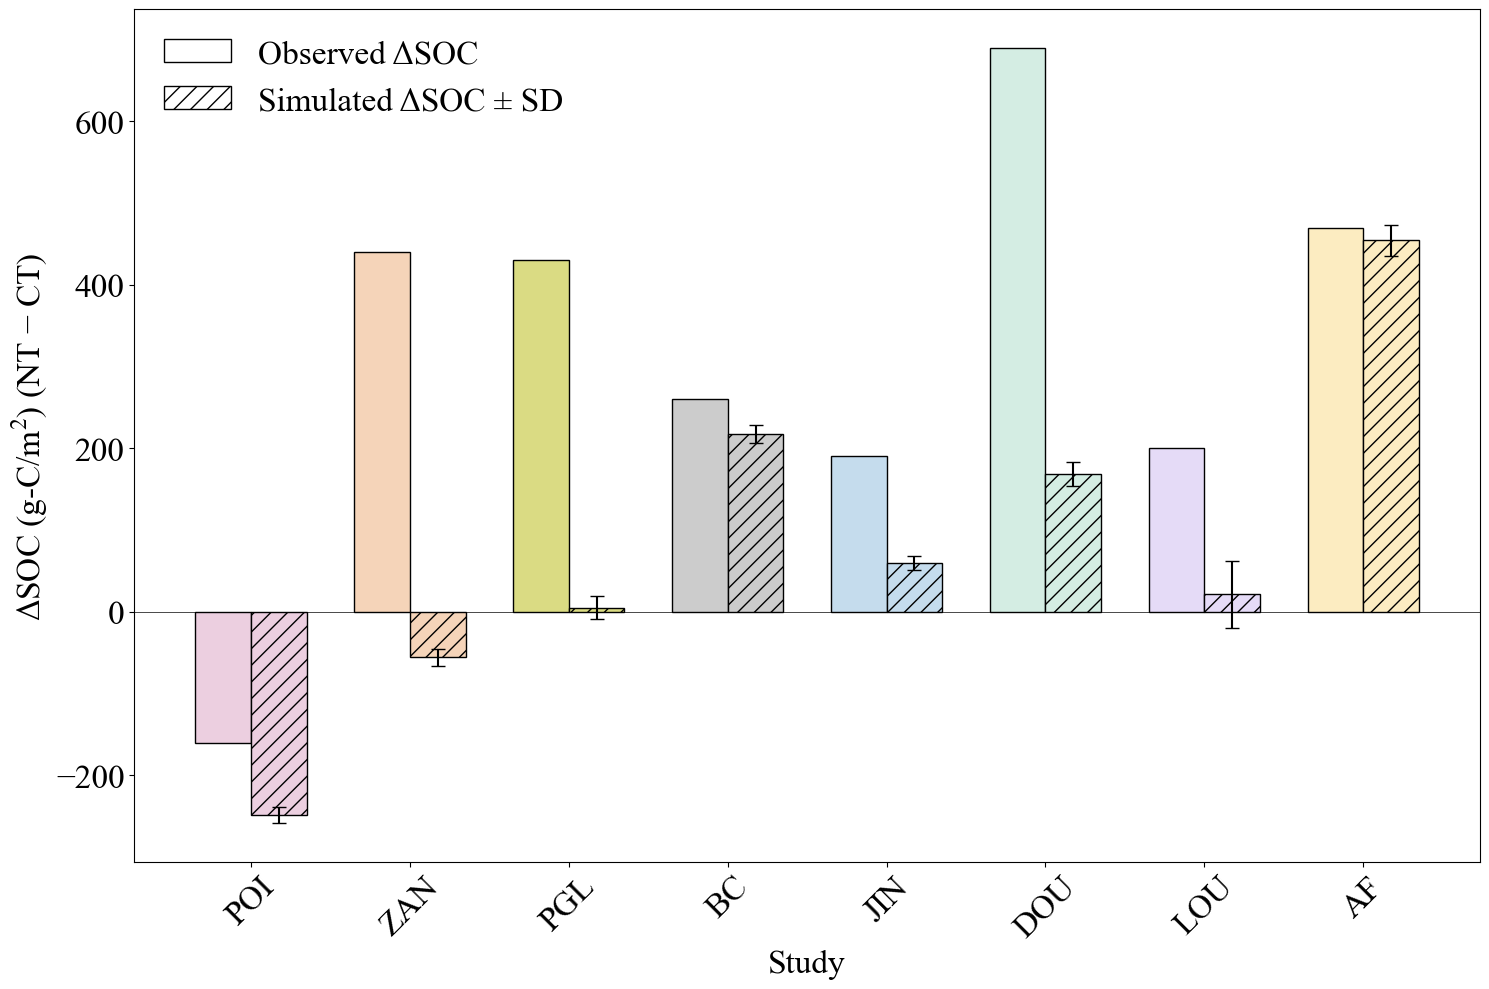


📊 ΔSOC (g-C/m²) for Each Study:
Study  Observed Delta SOC  Simulated Delta SOC  Delta SOC Std Dev
   AF                 470               454.70              19.00
   BC                 260               217.82              10.91
  DOU                 690               168.44              14.66
  JIN                 190                59.07               8.48
  LOU                 200                20.93              40.64
  PGL                 430                 4.92              14.10
  POI                -161              -248.61               9.82
  ZAN                 440               -56.14              10.45


In [13]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from matplotlib.patches import Patch

# -------- CONFIG --------
folder_path = 'C:\\Users\\rishabh.singh.AGNET\\OneDrive - Texas A&M AgriLife\\Desktop\\Slope\\Results'
obs_excel = os.path.join(folder_path, "gcb15001-sup-0001-tables1.xlsx")

study_colors = {
    "AF": "#fcecc1", "DOU": "#d4ede3", "JIN": "#c5dced", "LOU": "#e5dbf7",
    "POI": "#eccfe0", "PGL": "#dadb83", "ZAN": "#f5d4b9"
}

mpl.rcParams['font.family'] = 'Times New Roman'

# ---------------------------
# STEP 1: Load Observations
# ---------------------------
obs_df = pd.read_excel(obs_excel, sheet_name="SOC")
obs_df.columns = obs_df.columns.str.strip()
obs_df["Study"] = obs_df["Study"].str.strip().str.upper()
obs_df["Duration"] = obs_df["Study Duration"]

# ---------------------------
# STEP 2: Process Simulation Files
# ---------------------------
sim_results = []
pool_results = []

for filename in os.listdir(folder_path):
    if filename.endswith('.csv') and 'Higher' not in filename and 'Lower' not in filename and '_CENTURY' not in filename and '_Century' not in filename:
        study = filename.split('.')[0].strip().upper()
        if study not in obs_df["Study"].values:
            continue

        duration = obs_df.loc[obs_df["Study"] == study, "Duration"].values[0]
        end_year = 1500 + int(duration)

        df = pd.read_csv(os.path.join(folder_path, filename))
        required_cols = ['A', 'P', 'DOC', 'M', 'B', 'Years']
        if not all(col in df.columns for col in required_cols):
            print(f"⚠️ Skipping {filename} — missing required columns.")
            continue

        df["Year"] = pd.to_numeric(df["Years"], errors="coerce")
        df = df.dropna(subset=["Year"]).sort_values("Year")
        df["SOC"] = df[["A", "P", "DOC", "M", "B"]].sum(axis=1)

        # SOC_CT: Average from 1200–1400
        ct_soc = df.loc[df["Year"].between(1200, 1400), "SOC"]
        if ct_soc.empty:
            print(f"⚠️ Skipping {filename} — no data in CT window.")
            continue
        soc_ct = ct_soc.mean()
        std_ct = ct_soc.std()

        # SOC_NT: At end year (1500 + duration)
        if end_year in df["Year"].values:
            soc_nt = df.loc[df["Year"] == end_year, "SOC"].iloc[0]
        else:
            soc_nt = (
                df.set_index("Year")["SOC"]
                  .reindex(np.append(df["Year"].values, end_year))
                  .sort_index()
                  .interpolate("index")
                  .loc[end_year]
            )

        # ΔSOC = NT − CT
        delta_soc = soc_nt - soc_ct
        delta_std = std_ct  # Approximate error from CT side only

        sim_results.append({
            "Study": study,
            "Simulated Delta SOC": delta_soc,
            "Delta SOC Std Dev": delta_std
        })

sim_df = pd.DataFrame(sim_results)

# ---------------------------
# STEP 3: Merge & Sort
# ---------------------------
merged_df = pd.merge(obs_df, sim_df, on="Study", how="inner")

# Sort order logic
def assign_ai_bin(ai):
    if 0.5 <= ai < 1: return '[0.5-1)'
    elif 1 <= ai < 1.5: return '[1-1.5)'
    elif 1.5 <= ai < 2.5: return '[1.5-2.5)'
    elif 2.5 <= ai <= 4: return '[2.5-4)'
    else: return 'Out of range'

def assign_npp_class(row):
    if row['AI Bin'] in ['[0.5-1)', '[1-1.5)']:
        return 'Low NPP' if row['NPP'] <= 550 else 'High NPP'
    else:
        return 'NA'

merged_df['AI Bin'] = merged_df['AI'].apply(assign_ai_bin)
merged_df['NPP Class'] = merged_df.apply(assign_npp_class, axis=1)
bin_categories = ['[0.5-1)', '[1-1.5)', '[1.5-2.5)', '[2.5-4)']
npp_class_order = {'Low NPP': 0, 'High NPP': 1, 'NA': 2}
merged_df['AI Bin'] = pd.Categorical(merged_df['AI Bin'], categories=bin_categories, ordered=True)
merged_df['NPP Sort'] = merged_df['NPP Class'].map(npp_class_order)

# Sort and label
merged_df = merged_df.sort_values(['AI Bin', 'NPP Sort', 'AI', 'Study']).reset_index(drop=True)
merged_df['Label'] = merged_df.apply(
    lambda row: f"{row['AI Bin']} - {row['NPP Class']} | {row['Study']}"
    if row['NPP Class'] != 'NA' else f"{row['AI Bin']} | {row['Study']}",
    axis=1
)

print("✅ Studies processed:", sorted(merged_df['Study'].unique()))

# ---------------------------
# STEP 4: Plot
# ---------------------------
fig, ax = plt.subplots(figsize=(15, 10))
x = np.arange(len(merged_df))
width = 0.35

for i, row in merged_df.iterrows():
    study = row['Study']
    obs_val = row['Observed Delta SOC']
    sim_val = row['Simulated Delta SOC']
    sim_err = row['Delta SOC Std Dev']
    color = study_colors.get(study, "#cccccc")

    ax.bar(x[i] - width/2, obs_val, width, color=color, edgecolor='black',
           label='Observed ΔSOC' if i == 0 else "")
    ax.bar(x[i] + width/2, sim_val, width, color=color, edgecolor='black', hatch='//',
           yerr=sim_err, capsize=5,
           label='Simulated ΔSOC ± SD' if i == 0 else "")

ax.set_xlabel('Study', fontsize=24)
ax.set_ylabel(r'$\Delta$SOC (g-C/m$^2$) (NT − CT)', fontsize=24)
ax.set_xticks(x)
ax.set_xticklabels(merged_df['Study'], rotation=45, ha='center', fontsize=24)
ax.tick_params(axis='y', labelsize=24)
ax.axhline(y=0, color='black', linewidth=0.5)
ax.grid(False)

# Legend
legend_handles = [
    Patch(facecolor='white', edgecolor='black', label='Observed ΔSOC'),
    Patch(facecolor='white', edgecolor='black', hatch='//', label='Simulated ΔSOC ± SD')
]
ax.legend(handles=legend_handles, fontsize=24, frameon=False)
plt.savefig("Observed vs Simulated Delta SOC without steady state.pdf", format='pdf', bbox_inches='tight')
plt.tight_layout()
plt.show()

# ---------------------------
# STEP 5: Table Output
# ---------------------------
delta_soc_table = merged_df[['Study', 'Observed Delta SOC', 'Simulated Delta SOC', 'Delta SOC Std Dev']].copy()
delta_soc_table = delta_soc_table.sort_values(by='Study').reset_index(drop=True)
delta_soc_table[['Observed Delta SOC', 'Simulated Delta SOC', 'Delta SOC Std Dev']] = \
    delta_soc_table[['Observed Delta SOC', 'Simulated Delta SOC', 'Delta SOC Std Dev']].round(2)

print("\n📊 ΔSOC (g-C/m²) for Each Study:")
print(delta_soc_table.to_string(index=False))

# Tabular format for mean pool values under CT and NT

# Not under steady state


✅ Studies processed: ['AF', 'BC', 'DOU', 'JIN', 'LOU', 'PGL', 'POI', 'ZAN']


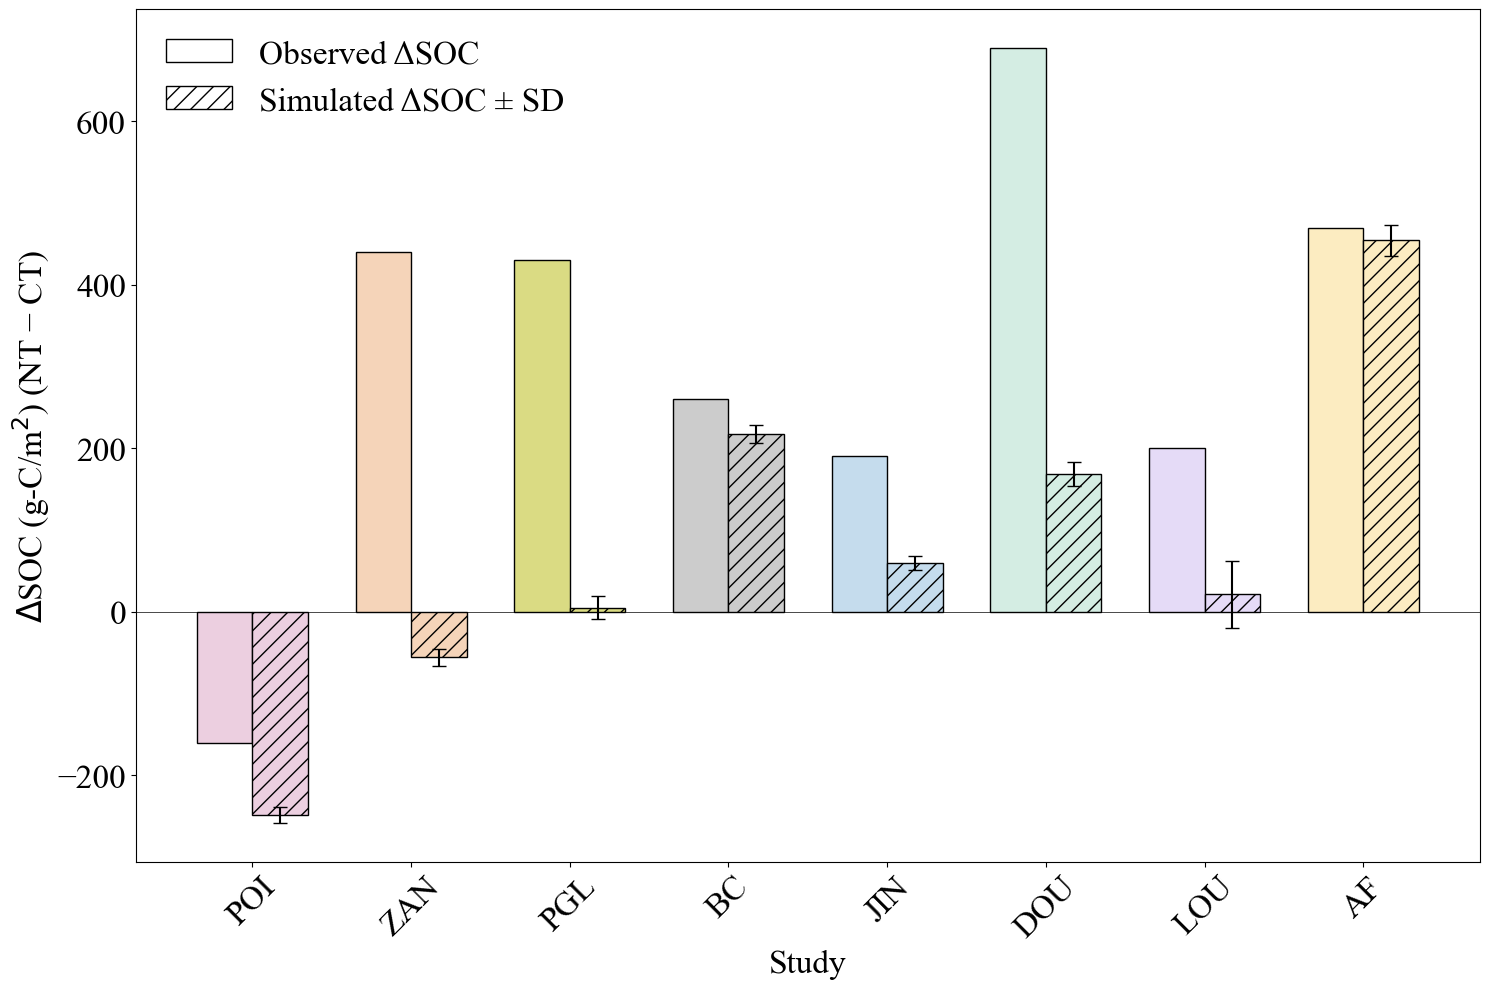


📊 ΔSOC (g-C/m²) for Each Study:
Study  Observed Delta SOC  Simulated Delta SOC  Delta SOC Std Dev
   AF                 470               454.70              19.00
   BC                 260               217.82              10.91
  DOU                 690               168.44              14.66
  JIN                 190                59.07               8.48
  LOU                 200                20.93              40.64
  PGL                 430                 4.92              14.10
  POI                -161              -248.61               9.82
  ZAN                 440               -56.14              10.45

📋 CT vs NT Pool Means (g-C/m²):
Study   AI    AI Bin   NPP NPP Class  Duration  CT_A_mean  CT_P_mean  CT_DOC_mean  CT_M_mean  CT_B_mean  CT_SOC_mean  NT_A_mean  NT_P_mean  NT_DOC_mean  NT_M_mean  NT_B_mean  NT_SOC_mean
  POI 0.63   [0.5-1) 456.3   Low NPP        13    1576.68     375.61       201.05    3242.92     208.84      5605.09    1735.04      60.34       200.41  

In [4]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from matplotlib.patches import Patch

folder_path = 'your folder path'
obs_excel = os.path.join(folder_path, "your excel file name.xlsx")

study_colors = {
    "AF": "#fcecc1", "DOU": "#d4ede3", "JIN": "#c5dced", "LOU": "#e5dbf7",
    "POI": "#eccfe0", "PGL": "#dadb83", "ZAN": "#f5d4b9"
}

mpl.rcParams['font.family'] = 'Times New Roman'

# STEP 1: Load Observations

obs_df = pd.read_excel(obs_excel, sheet_name="SOC")
obs_df.columns = obs_df.columns.str.strip()
obs_df["Study"] = obs_df["Study"].str.strip().str.upper()
obs_df["Duration"] = obs_df["Study Duration"]

# STEP 2: Process Simulation Files

sim_results = []
pool_results = []

for filename in os.listdir(folder_path):
    if filename.endswith('.csv') and 'Higher' not in filename and 'Lower' not in filename and '_CENTURY' not in filename and '_Century' not in filename:
        study = filename.split('.')[0].strip().upper()
        if study not in obs_df["Study"].values:
            continue

        duration = obs_df.loc[obs_df["Study"] == study, "Duration"].values[0]
        end_year = 1500 + int(duration)

        df = pd.read_csv(os.path.join(folder_path, filename))
        required_cols = ['A', 'P', 'DOC', 'M', 'B', 'Years']
        if not all(col in df.columns for col in required_cols):
            print(f"⚠️ Skipping {filename} — missing required columns.")
            continue

        df["Year"] = pd.to_numeric(df["Years"], errors="coerce")
        df = df.dropna(subset=["Year"]).sort_values("Year")
        df["SOC"] = df[["A", "P", "DOC", "M", "B"]].sum(axis=1)

        ct_window = df.loc[df["Year"].between(1200, 1400)]
        if ct_window.empty:
            print(f"⚠️ Skipping {filename} — no data in CT window.")
            continue

        ct_means = ct_window[["A", "P", "DOC", "M", "B", "SOC"]].mean()
        soc_ct = ct_means["SOC"]
        std_ct = ct_window["SOC"].std()

        if end_year in df["Year"].values:
            nt_vals = df.loc[df["Year"] == end_year, ["A", "P", "DOC", "M", "B", "SOC"]].iloc[0]
        else:
            df_interp = (df.set_index("Year")
                           .reindex(sorted(np.unique(np.append(df["Year"].values, end_year))))
                           .sort_index()
                           .interpolate("index"))
            nt_vals = df_interp.loc[end_year, ["A", "P", "DOC", "M", "B", "SOC"]]

        soc_nt = nt_vals["SOC"]
        delta_soc = soc_nt - soc_ct
        delta_std = std_ct

        sim_results.append({
            "Study": study,
            "Simulated Delta SOC": float(delta_soc),
            "Delta SOC Std Dev": float(delta_std)
        })

        pool_results.append({
            "Study": study,
            "Duration": int(duration),

            "CT_A_mean": float(ct_means["A"]),
            "CT_P_mean": float(ct_means["P"]),
            "CT_DOC_mean": float(ct_means["DOC"]),
            "CT_M_mean": float(ct_means["M"]),
            "CT_B_mean": float(ct_means["B"]),
            "CT_SOC_mean": float(ct_means["SOC"]),

            "NT_A_mean": float(nt_vals["A"]),
            "NT_P_mean": float(nt_vals["P"]),
            "NT_DOC_mean": float(nt_vals["DOC"]),
            "NT_M_mean": float(nt_vals["M"]),
            "NT_B_mean": float(nt_vals["B"]),
            "NT_SOC_mean": float(nt_vals["SOC"]),
        })

sim_df = pd.DataFrame(sim_results)

# STEP 3: Merge & Sort

merged_df = pd.merge(obs_df, sim_df, on="Study", how="inner")

def assign_ai_bin(ai):
    if 0.5 <= ai < 1: return '[0.5-1)'
    elif 1 <= ai < 1.5: return '[1-1.5)'
    elif 1.5 <= ai < 2.5: return '[1.5-2.5)'
    elif 2.5 <= ai <= 4: return '[2.5-4)'
    else: return 'Out of range'

def assign_npp_class(row):
    if row['AI Bin'] in ['[0.5-1)', '[1-1.5)']:
        return 'Low NPP' if row['NPP'] <= 550 else 'High NPP'
    else:
        return 'NA'

merged_df['AI Bin'] = merged_df['AI'].apply(assign_ai_bin)
merged_df['NPP Class'] = merged_df.apply(assign_npp_class, axis=1)
bin_categories = ['[0.5-1)', '[1-1.5)', '[1.5-2.5)', '[2.5-4)']
npp_class_order = {'Low NPP': 0, 'High NPP': 1, 'NA': 2}
merged_df['AI Bin'] = pd.Categorical(merged_df['AI Bin'], categories=bin_categories, ordered=True)
merged_df['NPP Sort'] = merged_df['NPP Class'].map(npp_class_order)

merged_df = merged_df.sort_values(['AI Bin', 'NPP Sort', 'AI', 'Study']).reset_index(drop=True)
merged_df['Label'] = merged_df.apply(
    lambda row: f"{row['AI Bin']} - {row['NPP Class']} | {row['Study']}"
    if row['NPP Class'] != 'NA' else f"{row['AI Bin']} | {row['Study']}",
    axis=1
)

print("✅ Studies processed:", sorted(merged_df['Study'].unique()))

# STEP 4: Plot

fig, ax = plt.subplots(figsize=(15, 10))
x = np.arange(len(merged_df))
width = 0.35

for i, row in merged_df.iterrows():
    study = row['Study']
    obs_val = row['Observed Delta SOC']
    sim_val = row['Simulated Delta SOC']
    sim_err = row['Delta SOC Std Dev']
    color = study_colors.get(study, "#cccccc")

    ax.bar(x[i] - width/2, obs_val, width, color=color, edgecolor='black',
           label='Observed ΔSOC' if i == 0 else "")
    ax.bar(x[i] + width/2, sim_val, width, color=color, edgecolor='black', hatch='//',
           yerr=sim_err, capsize=5,
           label='Simulated ΔSOC ± SD' if i == 0 else "")

ax.set_xlabel('Study', fontsize=24)
ax.set_ylabel(r'$\Delta$SOC (g-C/m$^2$) (NT − CT)', fontsize=24)
ax.set_xticks(x)
ax.set_xticklabels(merged_df['Study'], rotation=45, ha='center', fontsize=24)
ax.tick_params(axis='y', labelsize=24)
ax.axhline(y=0, color='black', linewidth=0.5)
ax.grid(False)

legend_handles = [
    Patch(facecolor='white', edgecolor='black', label='Observed ΔSOC'),
    Patch(facecolor='white', edgecolor='black', hatch='//', label='Simulated ΔSOC ± SD')
]
ax.legend(handles=legend_handles, fontsize=24, frameon=False)
plt.savefig("Observed vs Simulated Delta SOC without steady state.pdf", format='pdf', bbox_inches='tight')
plt.tight_layout()
plt.show()

# STEP 5: ΔSOC Table

delta_soc_table = merged_df[['Study', 'Observed Delta SOC', 'Simulated Delta SOC', 'Delta SOC Std Dev']].copy()
delta_soc_table = delta_soc_table.sort_values(by='Study').reset_index(drop=True)
delta_soc_table[['Observed Delta SOC', 'Simulated Delta SOC', 'Delta SOC Std Dev']] = \
    delta_soc_table[['Observed Delta SOC', 'Simulated Delta SOC', 'Delta SOC Std Dev']].round(2)

print("\n📊 ΔSOC (g-C/m²) for Each Study:")
print(delta_soc_table.to_string(index=False))

# STEP 6: CT vs NT Pool Means Table

pool_means_df = pd.DataFrame(pool_results)

meta_cols = ['Study', 'AI', 'AI Bin', 'NPP', 'NPP Class']
pool_means_df = (pool_means_df
                 .merge(merged_df[meta_cols].drop_duplicates('Study'), on='Study', how='left'))

cols_order = ['Study', 'AI', 'AI Bin', 'NPP', 'NPP Class', 'Duration',
              'CT_A_mean','CT_P_mean','CT_DOC_mean','CT_M_mean','CT_B_mean','CT_SOC_mean',
              'NT_A_mean','NT_P_mean','NT_DOC_mean','NT_M_mean','NT_B_mean','NT_SOC_mean']
pool_means_df = pool_means_df[cols_order]

round_cols = [c for c in pool_means_df.columns if c.endswith('_mean')]
pool_means_df[round_cols] = pool_means_df[round_cols].round(2)

pool_means_df['AI Bin'] = pd.Categorical(pool_means_df['AI Bin'], categories=bin_categories, ordered=True)
pool_means_df['NPP Sort'] = pool_means_df['NPP Class'].map(npp_class_order)
pool_means_df = pool_means_df.sort_values(['AI Bin','NPP Sort','AI','Study']).reset_index(drop=True)
pool_means_df = pool_means_df.drop(columns='NPP Sort')

print("\n📋 CT vs NT Pool Means (g-C/m²):")
print(pool_means_df.to_string(index=False))

out_excel = os.path.join(folder_path, "CT_vs_NT_pool_means.xlsx")
pool_means_df.to_excel(out_excel, index=False)
print(f"\n💾 Saved: {out_excel}")

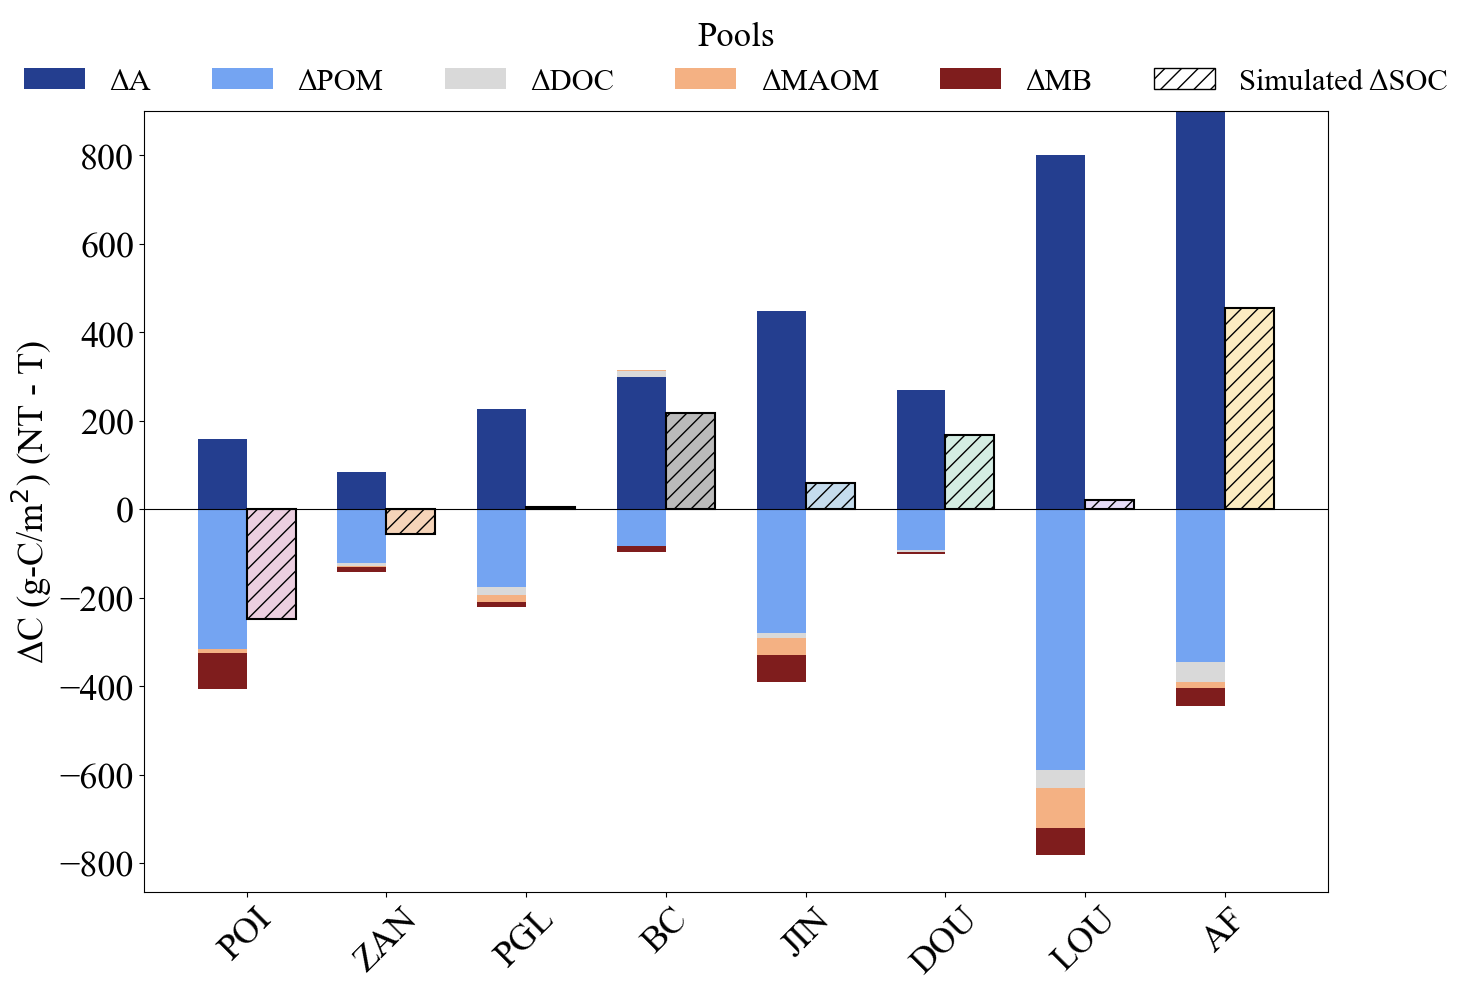

In [19]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from matplotlib.patches import Patch

folder_path = 'your folder path'
mpl.rcParams['font.family'] = 'Times New Roman'

# Define color map for simulated bars
study_colors = {
    "AF": "#fcecc1",  
    "DOU": "#d4ede3",  
    "JIN": "#c5dced",  
    "LOU": "#e5dbf7",  
    "POI": "#eccfe0", 
    "PGL": "#dadb83",  
    "ZAN": "#f5d4b9"
}


# STEP 1: Read Simulations with NT = 1500 + Duration

obs_df_duration = pd.read_excel("your excel file name.xlsx", sheet_name="your sheet name")
obs_df_duration.columns = obs_df_duration.columns.str.strip()
obs_df_duration["Study"] = obs_df_duration["Study"].str.strip().str.upper()
obs_df_duration = obs_df_duration.set_index("Study")

sim_results = []
pool_results = []

for filename in os.listdir(folder_path):
    if filename.endswith('.csv') and 'Higher' not in filename and 'Lower' not in filename:
        study_name = filename.split('.')[0].strip().upper()
        file_path = os.path.join(folder_path, filename)
        df = pd.read_csv(file_path)

        if not all(c in df.columns for c in ['A', 'P', 'DOC', 'M', 'B', 'Years']):
            continue

        df['Year'] = pd.to_numeric(df['Years'], errors='coerce')
        df = df.dropna(subset=['Year']).sort_values('Year')
        df['SOC'] = df[['A', 'P', 'DOC', 'M', 'B']].sum(axis=1)

        till_means = df.loc[df['Year'].between(1200, 1400), ['A', 'P', 'DOC', 'M', 'B', 'SOC']].mean()

        if study_name not in obs_df_duration.index:
            continue

        duration = obs_df_duration.loc[study_name, 'Study Duration']
        end_year = 1500 + int(duration)

        if end_year in df['Year'].values:
            nt_vals = df.loc[df['Year'] == end_year, ['A', 'P', 'DOC', 'M', 'B', 'SOC']].iloc[0]
        else:
            df_interp = df.set_index('Year').reindex(
                sorted(np.append(df['Year'].values, end_year))
            ).interpolate('index')
            nt_vals = df_interp.loc[end_year, ['A', 'P', 'DOC', 'M', 'B', 'SOC']]

        delta_soc = nt_vals['SOC'] - till_means['SOC']

        sim_results.append({'Study': study_name, 'Simulated Delta SOC': delta_soc})

        pool_results.append({
            'Study': study_name,
            'ΔA': nt_vals['A'] - till_means['A'],
            'ΔP': nt_vals['P'] - till_means['P'],
            'ΔDOC': nt_vals['DOC'] - till_means['DOC'],
            'ΔM': nt_vals['M'] - till_means['M'],
            'ΔB': nt_vals['B'] - till_means['B'],
            'Simulated ΔSOC': delta_soc
        })

sim_df = pd.DataFrame(sim_results)
pool_df = pd.DataFrame(pool_results)

# STEP 2: Read Observations and Sort

obs_df = pd.read_excel("gcb15001-sup-0001-tables1.xlsx", sheet_name="SOC")
obs_df.columns = obs_df.columns.str.strip()
obs_df['Study'] = obs_df['Study'].str.strip().str.upper()

def assign_ai_bin(ai):
    if 0.5 <= ai < 1:
        return '[0.5-1)'
    elif 1 <= ai < 1.5:
        return '[1-1.5)'
    elif 1.5 <= ai < 2.5:
        return '[1.5-2.5)'
    elif 2.5 <= ai <= 4:
        return '[2.5-4)'
    else:
        return 'Out of range'

def assign_npp_class(row):
    if row['AI Bin'] in ['[0.5-1)', '[1-1.5)']:
        return 'Low NPP' if row['NPP'] <= 550 else 'High NPP'
    else:
        return 'NA'

obs_df['AI Bin'] = obs_df['AI'].apply(assign_ai_bin)
obs_df['NPP Class'] = obs_df.apply(assign_npp_class, axis=1)

merged_df = pd.merge(obs_df, sim_df, on='Study', how='inner')

bin_categories = ['[0.5-1)', '[1-1.5)', '[1.5-2.5)', '[2.5-4)']
npp_class_order = {'Low NPP': 0, 'High NPP': 1, 'NA': 2}
merged_df['AI Bin'] = pd.Categorical(merged_df['AI Bin'], categories=bin_categories, ordered=True)
merged_df['NPP Sort'] = merged_df['NPP Class'].map(npp_class_order)

low_ai_bin_df = merged_df[merged_df['AI Bin'] == '[0.5-1)'].copy()
other_bins_df = merged_df[merged_df['AI Bin'] != '[0.5-1)'].copy()
low_ai_bin_df = low_ai_bin_df.sort_values(['AI', 'NPP Sort', 'Study'])
merged_df = pd.concat([low_ai_bin_df, other_bins_df], ignore_index=True)
merged_df = merged_df.sort_values(['AI Bin', 'NPP Sort', 'AI', 'Study']).reset_index(drop=True)

# Final labels
merged_df['Label'] = merged_df['Study']

# Align pool_df
pool_df['Study'] = pool_df['Study'].str.strip().str.upper()
pool_df = pool_df.set_index('Study').loc[merged_df['Study']].reset_index()

# STEP 3: Plot Side-by-Side Bars (Stacked + Simulated)

pools = ['ΔA', 'ΔP', 'ΔDOC', 'ΔM', 'ΔB']
colors = {
    'ΔA': '#243E8F',
    'ΔP': '#74A4F2',
    'ΔDOC': '#D9D9D9',
    'ΔM': '#F4B183',
    'ΔB': '#7F1D1D'
}

n = len(pool_df)
x = np.arange(n)
bar_width = 0.35

fig, ax = plt.subplots(figsize=(15, 10))

# --- Stacked Bars ---
positive_bottom = np.zeros(n)
negative_bottom = np.zeros(n)

for pool in pools:
    values = pool_df[pool].values
    pos_vals = np.where(values > 0, values, 0)
    neg_vals = np.where(values < 0, values, 0)

    ax.bar(x - bar_width/2, pos_vals, bottom=positive_bottom,
           width=bar_width, color=colors[pool], label=f'Difference_{pool[1:]}' if pool == 'ΔA' else "")
    ax.bar(x - bar_width/2, neg_vals, bottom=negative_bottom,
           width=bar_width, color=colors[pool])

    positive_bottom += pos_vals
    negative_bottom += neg_vals

# --- Simulated ΔSOC bars ---
for j, row in merged_df.iterrows():
    sim_val = row['Simulated Delta SOC']
    color = study_colors.get(row['Study'], '#bbbbbb')
    ax.bar(
        x[j] + bar_width/2, sim_val,
        width=bar_width,
        color=color,
        edgecolor="black",
        hatch='//',
        linewidth=1.5,
        label='Simulated ΔSOC' if j == 0 else ""
    )

# --- Axis & Labels ---
ax.set_xticks(x)
ax.set_xticklabels(merged_df['Label'], rotation=45, ha='center', fontsize=26)
ax.set_ylabel('ΔC (g-C/m$^2$) (NT - T)', fontsize=26)
ax.axhline(0, color='black', linewidth=0.8)
ax.tick_params(labelsize=26)

# --- Legend ---
legend_labels = {
    'ΔA': 'ΔA',
    'ΔP': 'ΔPOM',
    'ΔDOC': 'ΔDOC',
    'ΔM': 'ΔMAOM',
    'ΔB': 'ΔMB'
}

handles = [Patch(facecolor=colors[p], label=legend_labels[p]) for p in pools]
handles.append(Patch(facecolor='white', edgecolor='black', hatch='//', label='Simulated ΔSOC'))

ax.legend(
    handles=handles,
    fontsize=22,
    title='Pools',
    title_fontsize=25,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.15),  
    ncol=6,
    frameon=False
)

plt.tight_layout()
plt.savefig("Contribution of Pools to Delta SOC without steady state.pdf", format='pdf', bbox_inches='tight')
plt.show()